### Landnahme – Lösung Schritt für Schritt

*34. Bundeswettbewerb Informatik (2015), 1. Runde, Junioraufgabe 1*

Als der Westen noch wild war, konnte man sich seinen Traum von der kleinen Farm auf der Prärie leicht erfüllen. Man musste nur
das gewünschte Stück Land innerhalb von 24 Stunden zu Fuß umrunden und seinen Anspruch bei der Bürgermeisterin anmelden.

Da ihr bereits der Betrieb des Saloons genug Kopfzerbrechen machte, überließ die Bürgermeisterin dem Hilfssheriff, die
Umrundungen zu kontrollieren und die Ansprüche zu bearbeiten. Er könne zu allem Ja und Amen sagen und müsse nur darauf achten,
keinen Morgen Land ein zweites Mal zu vergeben. Der alte Knabe hatte zwar einst als Commodore in der Navy gedient, war beim
Rechnen aber nie der Flotteste gewesen. Deshalb hatte die Bürgermeisterin kurzerhand beschlossen, nur rechteckige und genau den
Himmelsrichtungen nach ausgerichtete Claims anzunehmen.

#### Junioraufgabe 1

Schreibe das Programm, das der alte Commodore gern gehabt hätte. Es liest als Eingabe eine Liste von Rechtecken in der Prärie,
jedes gegeben durch die Koordinaten von zwei sich gegenüberliegenden Ecken, und gibt die Liste wieder aus, wobei jedes Rechteck
korrekt als „genehmigt“ oder „abgelehnt“ gekennzeichnet ist. Genehmigt werden soll jedes Rechteck, das sich mit keinem früher
genehmigten Rechteck überschneidet.

Ein Beispiel:

| Eingabe | Ausgabe |
|---|---|
| `2 3 5 5` | `2 3 5 5 genehmigt` |
| `1 2 4 4` | `1 2 4 4 abgelehnt` |
| `3 1 6 3` | `3 1 6 3 genehmigt` |

*Freiwillige Zusatzaufgabe, ohne Einfluss auf die Bewertung:* Erstelle eine nette Visualisierung der Landnahme.

Im Beispiel berühren sich das erste und das dritte Rechteck an der Kante y = 3 und werden trotzdem beide genehmigt;
Berühren gilt also nicht als Überschneiden. Beispieldaten gibt es zu dieser Aufgabe nicht.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Geometrie von Rechtecken:** Zwei achsenparallele Rechtecke überschneiden sich genau dann **nicht**, wenn das eine links, rechts, oberhalb oder unterhalb des anderen liegt.
  Daraus folgt eine kurze Bedingung mit vier Vergleichen.
- **Normalisieren:** Die Eingabe gibt zwei gegenüberliegende Ecken in beliebiger Reihenfolge. Mit `min` und `max` bringt man jedes Rechteck in die Form (`xmin`, `ymin`, `xmax`, `ymax`).
- **Liste der bisherigen Ergebnisse:** Für jedes neue Rechteck prüft man alle schon genehmigten (lineare Suche). Abgelehnte Rechtecke zählen nicht, spätere auch nicht.
  Das ist ein **Online-Algorithmus**: Man entscheidet sofort, ohne die folgenden Rechtecke zu kennen.
- **Laufzeit:** Bei `n` Rechtecken sind es höchstens `n · (n − 1) / 2` Vergleiche (O(n²)).
- **Alternative für kleine ganze Koordinaten:** Man verwaltet die belegten Einheitsquadrate in einem Raster (Liste von Listen). Das ist anschaulich, aber langsam bei sehr großen Rechtecken.

**Nützliche Funktionen und Bibliotheken**
- `min`, `max`, `split`, `int`, f-Strings, `splitlines`
- Für die Visualisierung: `matplotlib.pyplot` (optional)

## Die Idee

Wir merken uns die genehmigten Rechtecke in einer Liste. Für jedes neue Rechteck vergleichen wir mit allen genehmigten:

- Liegt das neue Rechteck **ganz links** von einem genehmigten (`neu.xmax <= alt.xmin`), **ganz rechts** davon (`neu.xmin >= alt.xmax`), **ganz darunter** (`neu.ymax <= alt.ymin`) oder **ganz darüber**
  (`neu.ymin >= alt.ymax`), dann überschneiden sich die beiden nicht.
- Gilt **keiner** dieser vier Fälle, überschneiden sie sich, und das neue Rechteck wird abgelehnt.

Das `<=` und `>=` sorgt dafür, dass **Berühren** an einer Kante oder Ecke erlaubt ist, wie in der Aufgabenstellung beschrieben.
Eine Überprüfung nur der Ecken wäre falsch: Zwei Rechtecke können sich überkreuzen, ohne dass eine Ecke des einen im anderen liegt.

## Schritt 1: Ein Rechteck einlesen und normalisieren

Eine Zeile wie `3 1 6 3` enthält vier Zahlen: die Koordinaten zweier gegenüberliegender Ecken `(x1, y1)` und `(x2, y2)`. Welche Ecke zuerst steht, ist egal. Wir machen daraus die Form
`(xmin, ymin, xmax, ymax)` mit `min` und `max`, damit der Rest des Programms immer dieselbe Form bekommt.

Wir lesen Kommazahlen mit `float` ein, dann funktionieren auch Koordinaten wie `2.5`. (Würde man nur ganze Zahlen erwarten, ginge `int`.)

In [ ]:
def lies_rechteck(zeile):
    zahlen = zeile.split()
    x1 = float(zahlen[0])
    y1 = float(zahlen[1])
    x2 = float(zahlen[2])
    y2 = float(zahlen[3])
    return (min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2))


print(lies_rechteck('2 3 5 5'))
print(lies_rechteck('6 3 3 1'))        # gegenüberliegende Ecken in anderer Reihenfolge

(2.0, 3.0, 5.0, 5.0)
(3.0, 1.0, 6.0, 3.0)


## Schritt 2: Überschneiden sich zwei Rechtecke?

`ueberschneiden(r1, r2)` wendet die Idee an: Die Rechtecke überschneiden sich nicht, wenn eine der vier „Nicht-Bedingungen“ stimmt. Die Funktion gibt das Gegenteil zurück: `True`, wenn sie sich überschneiden.

In [ ]:
def ueberschneiden(r1, r2):
    x1min, y1min, x1max, y1max = r1
    x2min, y2min, x2max, y2max = r2
    links = x1max <= x2min              # r1 liegt ganz links von r2
    rechts = x1min >= x2max             # r1 liegt ganz rechts von r2
    darunter = y1max <= y2min           # r1 liegt ganz unter r2
    darueber = y1min >= y2max           # r1 liegt ganz über r2
    return not (links or rechts or darunter or darueber)


# Die wichtigen Fälle (Berühren, Überlappen, Enthalten, Überkreuzen)
a = (2, 3, 5, 5)
print('berühren (Kante):   ', ueberschneiden(a, (3, 1, 6, 3)))
print('berühren (Ecke):    ', ueberschneiden(a, (5, 5, 7, 7)))
print('überlappen:         ', ueberschneiden(a, (1, 2, 4, 4)))
print('enthalten:          ', ueberschneiden(a, (3, 4, 4, 5)))
print('umschließen:        ', ueberschneiden(a, (0, 0, 9, 9)))
print('überkreuzen:        ', ueberschneiden((0, 3, 9, 4), (4, 0, 5, 9)))
print('weit auseinander:   ', ueberschneiden(a, (10, 10, 12, 12)))

berühren (Kante):    False
berühren (Ecke):     False
überlappen:          True
enthalten:           True
umschließen:         True
überkreuzen:         True
weit auseinander:    False


Die ersten beiden Fälle (nur Berühren) sind **keine** Überschneidung. Alle anderen schon. Der Fall „überkreuzen“ ist der, den eine reine Prüfung der Ecken übersehen würde.

## Schritt 3: Die Landnahme

`landnahme(zeilen)` geht die Zeilen der Eingabe der Reihe nach durch. Die Liste `genehmigt` enthält die schon genehmigten Rechtecke. Für jedes neue Rechteck prüfen wir alle
genehmigten. Gibt es eine Überschneidung, wird es abgelehnt (und **nicht** gemerkt), sonst genehmigt und der Liste hinzugefügt.

Ein Wort noch zu den Zeilen: `text.splitlines()` zerlegt einen Text in seine Zeilen. Eine Datei liest man mit `f.read().splitlines()`. Leere Zeilen überspringen wir.

In [ ]:
def landnahme(zeilen):
    genehmigt = []
    ergebnis = []
    for zeile in zeilen:
        if zeile.strip() == '':
            continue
        rechteck = lies_rechteck(zeile)
        frei = True
        for altes in genehmigt:
            if ueberschneiden(rechteck, altes):
                frei = False
        if frei:
            genehmigt.append(rechteck)
            ergebnis.append((zeile.strip(), 'genehmigt'))
        else:
            ergebnis.append((zeile.strip(), 'abgelehnt'))
    return ergebnis


beispiel = """2 3 5 5
1 2 4 4
3 1 6 3"""

for zeile, urteil in landnahme(beispiel.splitlines()):
    print(zeile, urteil)

2 3 5 5 genehmigt
1 2 4 4 abgelehnt
3 1 6 3 genehmigt


Das ist genau die Ausgabe aus der Aufgabenstellung. Das zweite Rechteck überschneidet sich mit dem ersten, das dritte berührt es nur.

## Schritt 4: Mehr Tests

Es gibt keine Beispieldateien, deshalb denken wir uns selbst Fälle aus. Wir testen besonders die Stellen, an denen man leicht Fehler macht:
Berühren an Kante und Ecke, ein Rechteck innerhalb eines anderen, ein überkreuzendes Paar, ein abgelehntes Rechteck, das später kein Hindernis sein darf, vertauschte Ecken, negative und Kommazahlen.

In [ ]:
tests = """0 0 4 4
4 0 8 4
2 2 6 6
8 4 10 6
5 5 5.5 5.5
-3 -3 0 0
0 0 -2 -2
-1 -1 1 1
3 3 9 9
7 7 1 1"""

for zeile, urteil in landnahme(tests.splitlines()):
    print(f'{zeile:12} {urteil}')

0 0 4 4      genehmigt
4 0 8 4      genehmigt
2 2 6 6      abgelehnt
8 4 10 6     genehmigt
5 5 5.5 5.5  genehmigt
-3 -3 0 0    genehmigt
0 0 -2 -2    abgelehnt
-1 -1 1 1    abgelehnt
3 3 9 9      abgelehnt
7 7 1 1      abgelehnt


Zeile für Zeile:

1. `0 0 4 4` wird genehmigt (nichts davor).
2. `4 0 8 4` berührt das erste an der Kante x = 4 und wird genehmigt.
3. `2 2 6 6` überlappt beide und wird abgelehnt.
4. `8 4 10 6` berührt das zweite nur an der Ecke (8, 4) und wird genehmigt.
5. `5 5 5.5 5.5` ist frei und wird genehmigt (Kommazahlen sind kein Problem).
6. `-3 -3 0 0` berührt das erste nur an der Ecke (0, 0) und wird genehmigt.
7. `0 0 -2 -2` (vertauschte Ecken) liegt im sechsten Rechteck und wird abgelehnt. Das abgelehnte dritte Rechteck spielte dabei keine Rolle.
8. `-1 -1 1 1` überlappt das erste und das sechste und wird abgelehnt.
9. `3 3 9 9` überlappt das fünfte (und das vierte) und wird abgelehnt.
10. `7 7 1 1` überkreuzt gleich mehrere und wird abgelehnt.

## Für Neugierige: Visualisierung

Grüne Rechtecke sind genehmigt, rote abgelehnt (nur mit Rand). Wir zeichnen das Beispiel aus der Aufgabe und unsere Tests. `plt.Rectangle` erzeugt ein Rechteck (linke untere Ecke, Breite, Höhe),
`add_patch` fügt es zum Bild hinzu.

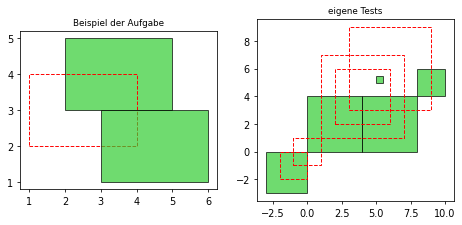

In [ ]:
import matplotlib.pyplot as plt


def zeichne(zeilen, titel, achse):
    for zeile, urteil in landnahme(zeilen):
        x1, y1, x2, y2 = lies_rechteck(zeile)
        if urteil == 'genehmigt':
            achse.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, facecolor='limegreen', edgecolor='black', alpha=0.7))
        else:
            achse.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linestyle='--'))
    achse.autoscale()
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=9)


bild, achsen = plt.subplots(1, 2, figsize=(8, 3.5))
zeichne(beispiel.splitlines(), 'Beispiel der Aufgabe', achsen[0])
zeichne(tests.splitlines(), 'eigene Tests', achsen[1])
plt.show()

**Die Rasterlösung für kleine ganze Koordinaten.** Statt Rechtecke zu vergleichen, kann man eine „Landkarte“ der belegten Einheitsquadrate führen: Ein neues Rechteck ist frei, wenn alle seine Einheitsquadrate frei sind.
Die Prüfung dauert dann so lange, wie das Rechteck Einheitsquadrate hat. Wir vergleichen beide Verfahren an Zufallsrechtecken (ganze Koordinaten von 0 bis 20).
`set` speichert die belegten Einheitsquadrate als Paare.

In [ ]:
def landnahme_raster(zeilen):
    belegt = set()
    ergebnis = []
    for zeile in zeilen:
        x1, y1, x2, y2 = lies_rechteck(zeile)
        felder = []
        for x in range(int(x1), int(x2)):
            for y in range(int(y1), int(y2)):
                felder.append((x, y))
        frei = True
        for feld in felder:
            if feld in belegt:
                frei = False
        if frei:
            for feld in felder:
                belegt.add(feld)
        ergebnis.append((zeile.strip(), 'genehmigt' if frei else 'abgelehnt'))
    return ergebnis


import random

random.seed(1)
gleich = True
for versuch in range(300):
    zeilen = []
    while len(zeilen) < 12:
        x1 = random.randint(0, 20)
        y1 = random.randint(0, 20)
        x2 = random.randint(0, 20)
        y2 = random.randint(0, 20)
        if x1 != x2 and y1 != y2:                   # nur Rechtecke mit Fläche
            zeilen.append(f'{x1} {y1} {x2} {y2}')
    if landnahme(zeilen) != landnahme_raster(zeilen):
        gleich = False
print('Rechtecke vergleichen und Raster liefern immer dasselbe:', gleich)

Rechtecke vergleichen und Raster liefern immer dasselbe: True


Rechtecke ohne Fläche (zum Beispiel `3 4 3 8`, eine Strecke) lassen wir bei diesem Vergleich weg. Sie sind ein Sonderfall, bei dem die beiden Verfahren verschieden urteilen können:
Eine solche Strecke mitten in einem genehmigten Rechteck wird beim Vergleichen als Überschneidung abgelehnt, das Raster dagegen sieht gar kein Einheitsquadrat und genehmigt sie.
In der Aufgabe kommen so schmale Rechtecke nicht vor (man muss ein Stück Land umrunden). Wer sie ausschließen will, lehnt Rechtecke mit Breite oder Höhe 0 gleich ab.